# 03 — Windowing, features, personal baseline and temporal context
PRD §9–11.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config, cleaning, features, baseline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
config.FIG_DIR.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(config.FIG_DIR / f'{name}.png', dpi=130)

In [2]:
ev = pd.read_csv(config.CLEAN_PATH, parse_dates=['timestamp'])
dur = ev.groupby(['user_id','session_id']).timestamp.agg(lambda t: (t.max()-t.min()).total_seconds())
print('session duration (s):'); print(dur.describe().round(1))

session duration (s):
count    1000.0
mean       13.9
std         3.0
min         8.1
25%        11.7
50%        13.4
75%        15.7
max        25.6
Name: timestamp, dtype: float64


Sessions last about 14 s, shorter than the 30-s window, so each 30-s window covers one whole session (1,000 windows). The window length is `config.WINDOW_S` if you want to experiment.

In [3]:
win = features.build_windows(ev)
print(win.shape); win[['user_id','session_id','window','n_events'] + config.CORE_FEATURES + ['mood_state','label_purity']].head()

(1000, 24)


,user_id,session_id,window,n_events,typing_speed,mean_dwell,std_dwell,mean_flight,std_flight,mean_pause,pause_count,long_pause_count,correction_rate,mood_state,label_purity
0,U001,1,0,100.0,6.755079,95.263402,26.547345,126.681067,55.598024,2262.251034,1.0,1.0,0.07,calm,0.32
1,U001,2,0,100.0,6.073889,98.454935,27.151917,118.524479,47.003586,2424.258912,2.0,2.0,0.08,calm,0.31
2,U001,3,0,100.0,6.735329,97.402555,34.232903,123.766074,52.882272,2594.242632,1.0,1.0,0.09,positive,0.31
3,U001,4,0,100.0,7.003443,94.210356,27.418519,124.551037,51.066628,1948.138606,1.0,0.0,0.05,positive,0.29
4,U001,5,0,100.0,8.319120,97.306716,29.495688,120.205023,52.238671,0.000000,0.0,0.0,0.09,positive,0.30


### Optional extended features (PRD §9)
Median dwell, dwell/flight coefficient of variation, char→char latency (the content-free stand-in for digraph latency; per-letter digraphs would need the characters we removed), mean burst length between pauses, and entropy of the key-category mix.

In [4]:
win[config.EXTENDED_FEATURES].describe().round(3)

,median_dwell,dwell_cv,flight_cv,char_char_latency,mean_burst_length,key_entropy
count,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000
mean,104.240,0.296,0.417,120.378,61.155,1.048
std,9.417,0.026,0.038,21.877,29.060,0.145
min,80.556,0.227,0.317,77.717,16.667,0.607
25%,96.892,0.278,0.391,104.277,33.333,0.951
50%,103.799,0.295,0.416,116.937,50.000,1.050
75%,110.680,0.311,0.440,132.756,100.000,1.146
max,130.428,0.392,0.582,213.362,100.000,1.437


## How clean is a window label?
Because the raw mood changes almost every keystroke, the window label is a majority vote over a mix of all four moods. `label_purity` is the share of the window's keystrokes that carry the majority label.

count    1000.000
mean        0.318
std         0.031
min         0.260
25%         0.300
50%         0.310
75%         0.340
max         0.450
Name: label_purity, dtype: float64
col_0         n
mood_state     
calm        630
low          27
positive    156
stressed    187


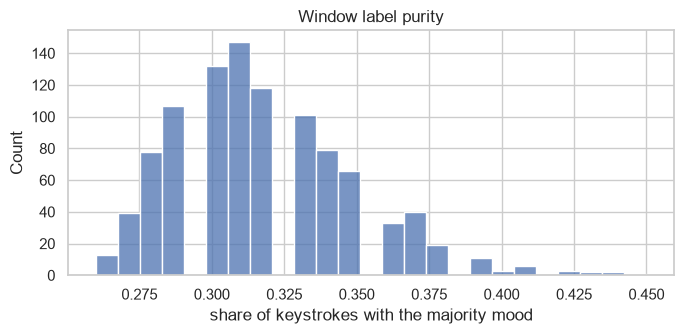

In [5]:
fig, ax = plt.subplots(figsize=(7,3.5)); sns.histplot(win.label_purity, bins=25, ax=ax); ax.set(title='Window label purity', xlabel='share of keystrokes with the majority mood'); save('fe_label_purity')
print(win.label_purity.describe().round(3))
print(pd.crosstab(win.mood_state, 'n'))

## Personal baseline (leave-one-out z-scores)
For each window: z = (value − mean of the user's other windows) / std of the user's other windows. No labels are used.

In [6]:
win = baseline.add_baseline_deviation(win)
u = win.user_id.iloc[0]
print(baseline.user_baseline(win, u).round(3))
win.loc[win.user_id == u, ['typing_speed', 'typing_speed_z', 'correction_rate', 'correction_rate_z']].head()

                  baseline_mean  baseline_std
typing_speed              6.841         1.016
mean_dwell               97.248         2.437
std_dwell                29.594         3.364
mean_flight             123.036         4.296
std_flight               52.338         5.872
mean_pause             1820.155      1105.308
pause_count               1.150         0.933
long_pause_count          1.000         0.858
correction_rate           0.084         0.019


,typing_speed,typing_speed_z,correction_rate,correction_rate_z
0,6.755079,-0.086570,0.07,-0.754129
1,6.073889,-0.785993,0.08,-0.212556
2,6.735329,-0.106500,0.09,0.319310
3,7.003443,0.164021,0.05,-1.983014
4,8.319120,1.586610,0.09,0.319310


## Temporal context
Change = current value − mean of the previous 3 windows of the same user (sessions are back to back in time).

In [7]:
win = baseline.add_temporal(win)
win.loc[win.user_id == u, ['window_start', 'typing_speed', 'typing_speed_change', 'pause_count', 'pause_count_change']].head(6)

,window_start,typing_speed,typing_speed_change,pause_count,pause_count_change
0,2026-01-01 09:00:00.107581429,6.755079,0.000000,1.0,0.000000
1,2026-01-01 09:00:14.961026823,6.073889,-0.681190,2.0,1.000000
2,2026-01-01 09:00:31.344916088,6.735329,0.320846,1.0,-0.500000
3,2026-01-01 09:00:46.237395900,7.003443,0.482011,1.0,-0.333333
4,2026-01-01 09:01:00.541677398,8.319120,1.714900,0.0,-1.333333
5,2026-01-01 09:01:12.488105536,6.887997,-0.464633,1.0,0.333333


In [8]:
win.to_csv(config.WINDOW_PATH, index=False)
print('saved', config.WINDOW_PATH.name, win.shape)

saved window_features.csv (1000, 42)


**Takeaway.** Mean label purity is ≈ 0.32: in a typical window only about a third of keystrokes carry the label the window is given, barely above the 0.25 of a random mix. Any classifier trained on these labels has a low ceiling, so results in notebook 04 must be read against chance, not against 100%.